In [1]:
# In practice dataset will store something like:

# duration_i = observed minutes

# status_i = 1 if unplug seen, 0 if censored

#EV under ToU vs. EV under 2-rates tariffs, potentially enriched with additional out of trial V2G data

# Initialisation

In [2]:
import polars as pl
import numpy as np
import pandas as pd 

import lifelines as ll
import matplotlib.pyplot as plt

## Functions

In [3]:
# Remove inactive peiods : vacation, metering issue...

def remove_inactive(df_interest, INACTIVE_KWH = 0.05, PROLONGED_DAYS = 30):

    df = df_interest.with_columns(
        (pl.col("kwh") < INACTIVE_KWH).alias("inactive")
    )

    inactive_runs = (
        df
        .sort(["household", "ts"])
        .with_columns(
            (
                pl.col("inactive")
                &
                ~pl.col("inactive").shift(1).over("household").fill_null(False) #“Was the previous record in this household active?”
            ).cast(pl.Int8).alias("start_run")
        )
        .with_columns(
            pl.col("start_run").cum_sum().over("household").alias("run_id")
        )
    )

    inactive_ep = (
        inactive_runs
        .filter(pl.col("inactive"))
        .group_by(["household", "run_id"])
        .agg([
            pl.col("ts").min().alias("start"),
            pl.col("ts").max().alias("end"),
            pl.count().alias("n_slots"),
        ])
        .with_columns(
            (pl.col("n_slots") / 48).alias("days")  # 48 half-hours/day
        )
    )

    inactive_ep = inactive_ep.with_columns(
        (pl.col("days") >= PROLONGED_DAYS).alias("prolonged")
    )

    # list_inactive = inactive_ep['household'].unique().to_list()

    # inactive_runs.filter(pl.col('inactive'))

    print(inactive_ep.filter(pl.col('prolonged')))

    ## Removing them from main dataset

    inactive_mask = (
        inactive_runs
        .join(
            inactive_ep.filter(pl.col("prolonged"))
            .select(["household", "run_id"]),
            on=["household", "run_id"],
            how="inner"
        )
        .select(["household", "ts"])
    )
    df_clean = df.join(
        inactive_mask,
        on=["household", "ts"],
        how="anti"
    )
    
    return df_clean

In [4]:
def find_charge_events(df_post_ev, Q = 0.99): # threshold quantile

    # high quantile method

    cols = ["household", "is_weekend", "season", 'time_period']

    ev_threshold = (
        df_post_ev
        .group_by(cols)
        .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("ev_threshold"))  
    )

    df_flagged = (
        df_post_ev
        .join(ev_threshold, on=cols)
        .with_columns(
            (
                pl.col("kwh")
                > pl.max_horizontal(pl.col("ev_threshold"), pl.lit(3))
            ).alias("ev_like")
        )
    )

    return df_flagged

In [5]:
def compute_freq(df): ## for visu
    cols = ["household", "is_weekend", "season", 'time_period']
    # Just the times to highlight
    charge_events = df.filter(pl.col("ev_like")).select(
        cols + ["ts", "kwh", "ev_threshold"]
    )

    plt.hist(charge_events['ev_threshold'])
    plt.title('Distribution of values above which we consider a charging event')

    # frequency
    freq_events = charge_events.group_by(["household"]).agg([
                pl.col("ts").count().alias("nb_of_events"),
                (pl.col('ts').max() - pl.col("ts").min()).alias("data_duration"),
                ((pl.col('ts').max() - pl.col("ts").min()).dt.total_days()/pl.col("ts").count()).alias("freq"),
            ]).sort(["freq", "nb_of_events"])

    print(freq_events)

    return freq_events

In [6]:
# def calculate_duration(df_flagged):

#     charges = (
#         df_flagged
#         .filter(pl.col("ev_like"))
#         .sort(["household", "ts"])
#     )

#     # detect new episode when gap > 1 hour
#     charges = charges.with_columns(
#         (
#             (pl.col("ts")
#             - pl.col("ts").shift(1).over("household")
#         ).dt.total_minutes()/60).fill_null(1).alias("gap_h")
#     )

#     charges = charges.with_columns(
#         (pl.col("gap_h") > 1).cast(pl.Int8).alias("new_episode")
#     )

#     charges = charges.with_columns(
#         pl.col("new_episode").cum_sum().over("household").alias("episode_id")
#     )

#     episodes = (
#         charges
#         .group_by(["household", "episode_id"])
#         .agg([
#             pl.col("ts").min().alias("start_ts"),
#             (pl.col("ts").max() + pl.duration(minutes=30)).alias("end_ts"),
#         ])
#         .sort(["household", "start_ts"])
#     )

#     return episodes

In [7]:
def gen_df_events(df_flagged): # for each household list their charge events by episode id and their start and end
    
    charges = (
        df_flagged
        .filter(pl.col("ev_like"))
        .sort(["household", "ts"])
    )
    

    # detect new episode when gap > 1 hour
    charges = charges.with_columns(
        (
            (pl.col("ts")
            - pl.col("ts").shift(1).over("household")
        ).dt.total_minutes()/60).fill_null(1).alias("gap_h")
    )
    
    charges = charges.with_columns(
        (pl.col("gap_h") > 1).cast(pl.Int8).alias("new_episode")
    )
    
    charges = charges.with_columns(
        (pl.col("new_episode").cum_sum().over("household") + 1).alias("episode_id")
    )


    episodes = (
        charges
        .group_by(["household", "episode_id"])
        .agg([
            pl.col("ts").min().alias("start_ts"),
            (pl.col("ts").max() + pl.duration(minutes=30)).alias("end_ts"),
        ])
        .sort(["household", "start_ts"])
    )

    return episodes

In [8]:
def calculate_gaps(episodes): 
    
    gap_times = (
    episodes
    .with_columns(
        pl.col("start_ts").shift(-1).over("household").alias("next_start")
    )
    .filter(pl.col("next_start").is_not_null())
    .with_columns(
        ((pl.col("next_start") - pl.col("end_ts")).dt.total_minutes()/60).alias("gap_hours_till_next_charge")
    )
    # .select(["household", "start_ts", "end_ts", "next_start", "gap_hours_till_next_charge"])
    )

    return gap_times

In [9]:
def plot_client_with_charging(df_flagged: pl.DataFrame, household_name: str):
    d = (
        df_flagged
        .filter(pl.col("household") == household_name)
        .select(["ts", "kwh", "ev_like"])
        .sort("ts")
        .to_pandas()
    )

    fig, ax = plt.subplots(figsize=(12,4))
    ax.plot(d["ts"], d["kwh"], label="Consumption (kWh)")

    # highlight flagged hours
    m = d["ev_like"].astype(bool)
    ax.scatter(d.loc[m, "ts"], d.loc[m, "kwh"], color="red", s=12, label="Charging events")

    ax.set_title(f"Household {household_name}: consumption with EV charging highlighted")
    ax.set_ylabel("kWh per hour")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [10]:
def clean_df(data: str):
    path = f"../data/{data}ConsolideNEW.csv"
    df = pl.read_csv(path)

    time_col = df.columns[0]  # the unnamed time column (first column)

    df = (
        df.with_columns(
            [
                pl.col(time_col).str.strptime(pl.Datetime, strict=False).alias("ts"),
                pl.exclude(time_col).cast(pl.Float64),
            ]
        )
    ).drop([df.columns[0]])

    df = (
    df.unpivot(index=["ts"])
      .rename({"variable": "household", "value": "kwh"})
      .sort(["household", "ts"])
      .with_columns([
          pl.col("ts")
            .dt.strftime("%w")
            .cast(pl.Int8)
            .is_in([0, 6])
            .cast(pl.Int8)
            .alias("is_weekend"),

          pl.col("ts").dt.month().alias("month"),
      ])
      .with_columns([
          # season
          pl.when(pl.col("month").is_in([12, 1, 2]))
            .then(pl.lit("winter"))
            .when(pl.col("month").is_in([3, 4, 5]))
            .then(pl.lit("spring"))
            .when(pl.col("month").is_in([6, 7, 8]))
            .then(pl.lit("summer"))
            .otherwise(pl.lit("autumn"))
            .alias("season"),

          # time period
          pl.when(pl.col("is_weekend") == 1)
            # WEEKEND
            .then(
                pl.when(pl.col("ts").dt.hour() < 8)
                  .then(pl.lit("offpeak"))
                  .when(pl.col("ts").dt.hour().is_between(16, 20))
                  .then(pl.lit("peak"))
                  .otherwise(pl.lit("mid"))
            )
            # WEEKDAY
            .otherwise(
                pl.when(pl.col("ts").dt.hour() < 8)
                  .then(pl.lit("offpeak"))
                  .otherwise(pl.lit("mid"))
            )
            .alias("time_period"),
      ])
      .drop("month")
)
    
    df = df.with_columns(
    pl.col("kwh").fill_null(0)
)

    return df


# Exploration

In [11]:
df_C = clean_df('controle')
df_I = clean_df('intervention')

In [13]:
df_C.head()

ts,household,kwh,is_weekend,season,time_period
datetime[μs],str,f64,i8,str,str
2025-01-02 00:00:00,"""03efd9cce89d44d9a78d085c240476…",0.157,0,"""winter""","""offpeak"""
2025-01-02 00:30:00,"""03efd9cce89d44d9a78d085c240476…",0.151,0,"""winter""","""offpeak"""
2025-01-02 01:00:00,"""03efd9cce89d44d9a78d085c240476…",0.475,0,"""winter""","""offpeak"""
2025-01-02 01:30:00,"""03efd9cce89d44d9a78d085c240476…",0.14,0,"""winter""","""offpeak"""
2025-01-02 02:00:00,"""03efd9cce89d44d9a78d085c240476…",0.347,0,"""winter""","""offpeak"""


In [12]:
print(df_C['household'].unique().shape,
      df_I['household'].unique().shape)

(89,) (110,)


In [15]:
# Real data duration

# clients_duration = df_C.filter(pl.col('kwh') > 0.1).group_by(['household']).agg([
#             (pl.col("ts").max() - pl.col("ts").min()).alias("no_zero_duration"),
#         ]).sort('no_zero_duration')

# clients_duration

## Removing unexploitable data 

### Inactive or not?

In [16]:
df_C_clean = remove_inactive(df_C)

shape: (9, 7)
┌─────────────────────────┬────────┬──────────────┬──────────────┬─────────┬───────────┬───────────┐
│ household               ┆ run_id ┆ start        ┆ end          ┆ n_slots ┆ days      ┆ prolonged │
│ ---                     ┆ ---    ┆ ---          ┆ ---          ┆ ---     ┆ ---       ┆ ---       │
│ str                     ┆ i64    ┆ datetime[μs] ┆ datetime[μs] ┆ u32     ┆ f64       ┆ bool      │
╞═════════════════════════╪════════╪══════════════╪══════════════╪═════════╪═══════════╪═══════════╡
│ 58f08adbcb5a124d347040f ┆ 1      ┆ 2025-01-02   ┆ 2025-02-04   ┆ 1631    ┆ 33.979167 ┆ true      │
│ bae3e2e…                ┆        ┆ 00:00:00     ┆ 23:00:00     ┆         ┆           ┆           │
│ 79f6f18dc8a3b0f9d45859f ┆ 4      ┆ 2025-02-14   ┆ 2025-04-03   ┆ 2304    ┆ 48.0      ┆ true      │
│ f53b6c4…                ┆        ┆ 00:00:00     ┆ 00:30:00     ┆         ┆           ┆           │
│ e9841079beed2eea5f907cf ┆ 9      ┆ 2025-05-05   ┆ 2025-06-18   ┆ 2112    ┆ 

C:\Users\duval1e\AppData\Local\Temp\ipykernel_19800\740508310.py:31: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("n_slots"),


In [17]:
df_I_clean = remove_inactive(df_I)

shape: (6, 7)
┌────────────────────────┬────────┬──────────────┬──────────────┬─────────┬────────────┬───────────┐
│ household              ┆ run_id ┆ start        ┆ end          ┆ n_slots ┆ days       ┆ prolonged │
│ ---                    ┆ ---    ┆ ---          ┆ ---          ┆ ---     ┆ ---        ┆ ---       │
│ str                    ┆ i64    ┆ datetime[μs] ┆ datetime[μs] ┆ u32     ┆ f64        ┆ bool      │
╞════════════════════════╪════════╪══════════════╪══════════════╪═════════╪════════════╪═══════════╡
│ e1b7efcf8c47ea46de70d9 ┆ 2      ┆ 2025-04-30   ┆ 2025-09-02   ┆ 6001    ┆ 125.020833 ┆ true      │
│ 596a4efe…              ┆        ┆ 01:00:00     ┆ 01:00:00     ┆         ┆            ┆           │
│ 61cfe913c5ba60c78405bc ┆ 2      ┆ 2025-05-27   ┆ 2025-09-02   ┆ 4707    ┆ 98.0625    ┆ true      │
│ 144da609…              ┆        ┆ 00:00:00     ┆ 01:00:00     ┆         ┆            ┆           │
│ 354606ffd532653269fe58 ┆ 3      ┆ 2025-05-31   ┆ 2025-09-02   ┆ 4513    ┆ 9

C:\Users\duval1e\AppData\Local\Temp\ipykernel_19800\740508310.py:31: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("n_slots"),


### EV converted or not?

In [18]:
#Clients with big quantile 95 plateaux
#from the graph lets choose to consider a jump from 2.7 
#wich is reasonable cuz usually CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]


def remove_pre_EV(df, EV_JUMP = 1.8):  # kWh or equivalent monthly peak jump granny charging is common for Early EV adopters

    diff_q = (
        df
        .sort("ts")
        .group_by_dynamic(
            index_column="ts",
            every="1w",
            closed="left",
            group_by="household"
        )
        .agg(
            pl.col("kwh").quantile(0.95).alias("q95")
        ) ### find max of all monthly maximums to see if a big jump happens (also min of all max course)
        .sort(["household", "ts"])
    )

    diff_q = diff_q.with_columns(
        pl.col("q95").diff().over("household").alias("dq95")
    )

    diff_q = diff_q.with_columns(
        (pl.col("dq95") > EV_JUMP).alias("jump_candidate")
    )

    diff_q = diff_q.with_columns(
        pl.col("q95")
        .rolling_mean(13) ## duration of a season
        .shift(-12) # to compute forward
        .over("household")
        .alias("q95_smooth")
    )

    diff_q = diff_q.with_columns(
        (
            pl.col("jump_candidate")
            &
            (
                pl.col("q95_smooth")
                >
                pl.col("q95").shift(1).over("household") + EV_JUMP
            )
        ).alias("ev_adopted")
    )

    ev_start = (
        diff_q
        .filter(pl.col("ev_adopted"))
        .group_by("household")
        .agg(pl.col("ts").min().alias("ev_start_ts"))
    )

    # list_converted = ev_start['household'].unique().to_list()

    ## Removing them from main dataset

    pre_ev_mask = (
        df
        .join(ev_start, on="household", how="inner")
        .filter(pl.col("ts") < pl.col("ev_start_ts"))
        .select(["household", "ts"])
    )

    df_post_ev = df.join(
        pre_ev_mask,
        on=["household", "ts"],
        how="anti"
    )

    # Every household starts at its EV adoption time
    check = (
        df_post_ev
        .group_by("household")
        .agg(pl.col("ts").min().alias("first_ts"))
        .join(ev_start, on="household")
        .with_columns(
            (pl.col("first_ts") == pl.col("ev_start_ts")).alias("ok") #after cleaning, does each household start exactly at ev_start_ts?
        )
    )

    bad = check.filter(~pl.col("ok")).select(
    "household", "first_ts", "ev_start_ts"
    )

    print(bad)



    print(check.filter(~pl.col("ok")).is_empty())

    return df_post_ev

In [19]:
df_C_post_ev = remove_pre_EV(df_C_clean)
df_I_post_ev = remove_pre_EV(df_I_clean)

shape: (0, 3)
┌───────────┬──────────────┬──────────────┐
│ household ┆ first_ts     ┆ ev_start_ts  │
│ ---       ┆ ---          ┆ ---          │
│ str       ┆ datetime[μs] ┆ datetime[μs] │
╞═══════════╪══════════════╪══════════════╡
└───────────┴──────────────┴──────────────┘
True
shape: (0, 3)
┌───────────┬──────────────┬──────────────┐
│ household ┆ first_ts     ┆ ev_start_ts  │
│ ---       ┆ ---          ┆ ---          │
│ str       ┆ datetime[μs] ┆ datetime[μs] │
╞═══════════╪══════════════╪══════════════╡
└───────────┴──────────────┴──────────────┘
True


### More plots

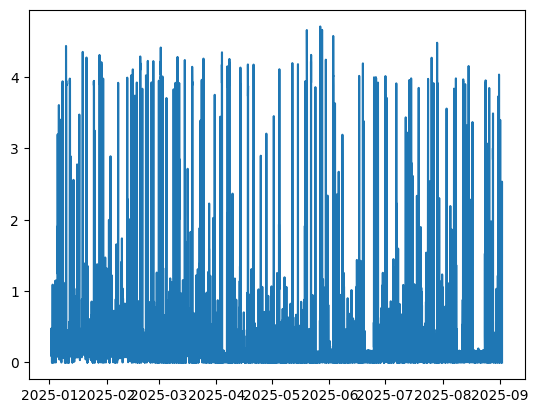

: 

In [ ]:
client = df_C_post_ev.filter(pl.col('household') == "03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b76ee18ef4a83ef34d3")
plt.plot(client['ts'], client['kwh'])
plt.show()

In [ ]:
# high quantile method

Q = 0.99 # threshold quantile 

cols = ["household", "is_weekend", "season", 'time_period']

ev_threshold = (
    df_C_post_ev
    .group_by(cols)
    .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("ev_threshold"))  
)

df_flagged_C = (
    df_C_post_ev
    .join(ev_threshold, on=cols)
    .with_columns(
        (
            pl.col("kwh")
            > pl.max_horizontal(pl.col("ev_threshold"), pl.lit(1.8))
        ).alias("ev_like")
    )
)

# Just the times to highlight
charge_events = df_flagged_C.filter(pl.col("ev_like")).select(
    cols + ["ts", "kwh", "ev_threshold"]
)



: 

Text(0.5, 1.0, 'Distribution of consumption plateaux differences across all households')

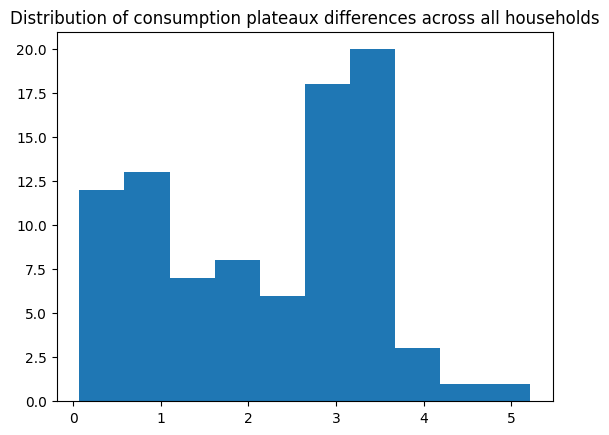

: 

In [ ]:
# gaps between high plateaux? JUST FOR VISU

df = (
    df_C_post_ev
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").quantile(0.95).alias("q95")
    ) ### find max of all monthly maximums to see if a big jump happens (also min of all max course)
    .group_by("household")
    .agg([
        (pl.col("q95").max()-pl.col("q95").min()).alias("diff_q95"), 
    ])
)

plt.hist(df['diff_q95'])
plt.title('Distribution of consumption plateaux differences across all households')

Text(0.5, 1.0, 'Distribution of consumption max differences across all households')

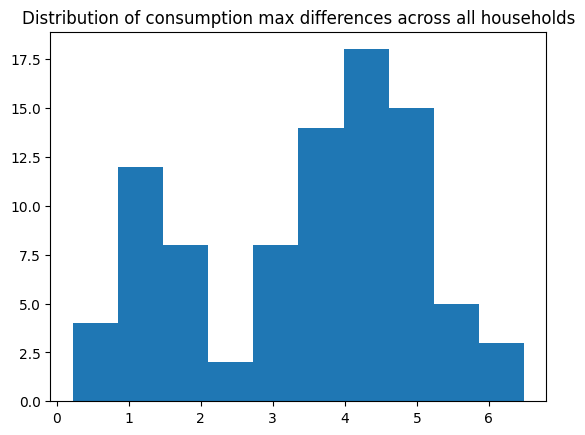

: 

In [ ]:
# gaps between high plateaux? JUST FOR VISU 

df = (
    df_C_post_ev
    .sort("ts")
    .group_by_dynamic(
        index_column="ts",
        every="1mo",
        closed="left",
        group_by="household"
    )
    .agg(
        pl.col("kwh").max().alias("window_max")
    ) ### find max of all monthly maximums to see if a big jump happens (also min of all max course)
    .group_by("household")
    .agg([
        (pl.col("window_max").max()-pl.col("window_max").min()).alias("diff_window_max"), 
    ])
)

plt.hist(df['diff_window_max'])
plt.title('Distribution of consumption max differences across all households')

## Creation of events df

In [20]:
df_flagged_C = find_charge_events(df_C_post_ev)
df_flagged_I = find_charge_events(df_I_post_ev)

shape: (89, 4)
┌─────────────────────────────────┬──────────────┬───────────────┬──────────┐
│ household                       ┆ nb_of_events ┆ data_duration ┆ freq     │
│ ---                             ┆ ---          ┆ ---           ┆ ---      │
│ str                             ┆ u32          ┆ duration[μs]  ┆ f64      │
╞═════════════════════════════════╪══════════════╪═══════════════╪══════════╡
│ 85aa9e4bd7cba7b61ae01d85c00b70… ┆ 116          ┆ 217d 6h 30m   ┆ 1.87069  │
│ 8f96a65b5ed6aa48a0f9931d7eb236… ┆ 47           ┆ 90d 8h 30m    ┆ 1.914894 │
│ 27b02a005ce819109184d5b5cf1aa1… ┆ 88           ┆ 169d 22h      ┆ 1.920455 │
│ 4301c2a55ca0b40179f0106ba29bfa… ┆ 81           ┆ 156d 4h 30m   ┆ 1.925926 │
│ 5f7a750fba962ce752531159bff380… ┆ 114          ┆ 220d 4h 30m   ┆ 1.929825 │
│ …                               ┆ …            ┆ …             ┆ …        │
│ e2638a3779a287c5e5258ed9a42c2e… ┆ 36           ┆ 230d 1h 30m   ┆ 6.388889 │
│ 8e19d5580ce5a3d120ac3eee05eb02… ┆ 36           

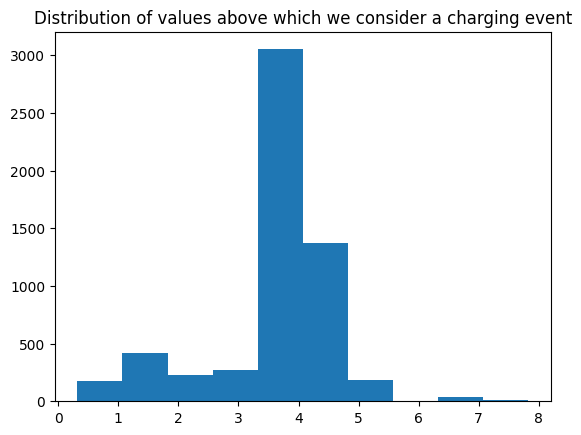

In [21]:
charge_events_C = compute_freq(df_flagged_C)

shape: (110, 4)
┌─────────────────────────────────┬──────────────┬───────────────┬──────────┐
│ household                       ┆ nb_of_events ┆ data_duration ┆ freq     │
│ ---                             ┆ ---          ┆ ---           ┆ ---      │
│ str                             ┆ u32          ┆ duration[μs]  ┆ f64      │
╞═════════════════════════════════╪══════════════╪═══════════════╪══════════╡
│ 26fdfd805a0945ed561927a3ae4cce… ┆ 3            ┆ 1h            ┆ 0.0      │
│ 12a53c70a04c7e98b39074288c4329… ┆ 100          ┆ 157d 7h       ┆ 1.57     │
│ 6e4396c5aa30d3583f2eb77045a8cd… ┆ 83           ┆ 144d 6h 30m   ┆ 1.73494  │
│ e4bbce24b0d04ad309557231b52a4f… ┆ 93           ┆ 175d 9h 30m   ┆ 1.88172  │
│ bc020bf7dd656fda300f7b752ce81e… ┆ 111          ┆ 213d 21h      ┆ 1.918919 │
│ …                               ┆ …            ┆ …             ┆ …        │
│ 580066181863b081dbd56fc7972994… ┆ 37           ┆ 228d 23h 30m  ┆ 6.162162 │
│ fe18b46b416a7f24cedeac9604de9b… ┆ 38          

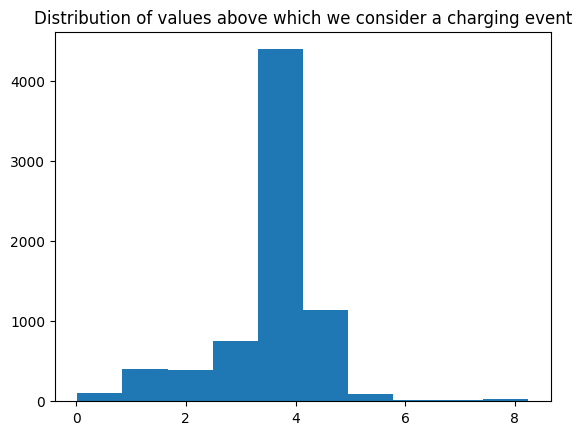

In [22]:
charge_events_I = compute_freq(df_flagged_I)

In [29]:
# median + charger excess

# Q = 0.5               # baseline quantile 
# CHARGER_KW_OPTIONS = [2.3, 3.6, 7.0]
# TOL = 0.35

# #control
# ##baseline sur energie soutenue 1h 

# cols = ["household", "is_weekend", "season", 'time_period']

# baseline = (
#     df_C
#     .group_by(cols)
#     .agg(pl.col("kwh").quantile(Q, interpolation="nearest").alias("baseline"))  
# )

# df_flagged_C = (
#     df_C
#     .join(baseline, on=cols)
#     .with_columns([
#         (pl.col("kwh") - pl.col("baseline")).clip(lower_bound = 0).alias("excess_kwh"),
#     ])
#     .with_columns([
#         # flag if excess matches any typical charger size (within tolerance)
#         pl.any_horizontal([
#             pl.col("excess_kwh").is_between(kw * (1 - TOL), kw * (1 + TOL)) #--- ev no ev
#             for kw in CHARGER_KW_OPTIONS
#         ]).alias("ev_like"),
#     ])
# )

# # Just the times to highlight
# df_flagged_C.filter(pl.col("ev_like")).select(
#     ["ts", "season", "household", "kwh", "baseline", "excess_kwh", 'time_period']
# )


# Survival models

## Gap-time model Cox model

### Control

In [23]:
episodes_C = gen_df_events(df_flagged_C)
episodes_I = gen_df_events(df_flagged_I)

In [24]:
episodes_C

household,episode_id,start_ts,end_ts
str,i64,datetime[μs],datetime[μs]
"""03efd9cce89d44d9a78d085c240476…",1,2025-01-05 12:30:00,2025-01-05 13:00:00
"""03efd9cce89d44d9a78d085c240476…",2,2025-01-10 00:30:00,2025-01-10 01:00:00
"""03efd9cce89d44d9a78d085c240476…",3,2025-01-19 00:30:00,2025-01-19 01:00:00
"""03efd9cce89d44d9a78d085c240476…",4,2025-01-21 01:00:00,2025-01-21 01:30:00
"""03efd9cce89d44d9a78d085c240476…",5,2025-01-25 11:00:00,2025-01-25 11:30:00
…,…,…,…
"""fff1cfde616f1b03a9b23a1d5385bb…",20,2025-06-22 00:30:00,2025-06-22 02:00:00
"""fff1cfde616f1b03a9b23a1d5385bb…",21,2025-07-05 00:30:00,2025-07-05 01:00:00
"""fff1cfde616f1b03a9b23a1d5385bb…",22,2025-07-11 01:30:00,2025-07-11 02:00:00


In [25]:
gap_times_C = calculate_gaps(episodes_C).to_pandas()
gap_times_C['intervention'] = 0

gap_times_I = calculate_gaps(episodes_I).to_pandas()
gap_times_I['intervention'] = 1

gap_times = pd.concat([gap_times_C, gap_times_I])
gap_times

,household,episode_id,start_ts,end_ts,next_start,gap_hours_till_next_charge,intervention
0,03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b...,1,2025-01-05 12:30:00,2025-01-05 13:00:00,2025-01-10 00:30:00,107.5,0
1,03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b...,2,2025-01-10 00:30:00,2025-01-10 01:00:00,2025-01-19 00:30:00,215.5,0
2,03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b...,3,2025-01-19 00:30:00,2025-01-19 01:00:00,2025-01-21 01:00:00,48.0,0
3,03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b...,4,2025-01-21 01:00:00,2025-01-21 01:30:00,2025-01-25 11:00:00,105.5,0
4,03efd9cce89d44d9a78d085c240476ebddb7c2f7282e9b...,5,2025-01-25 11:00:00,2025-01-25 11:30:00,2025-01-28 01:30:00,62.0,0
...,...,...,...,...,...,...,...
3953,fe18b46b416a7f24cedeac9604de9b14f5dbf5222127e3...,19,2025-07-29 00:30:00,2025-07-29 01:00:00,2025-08-01 00:30:00,71.5,1
3954,fe18b46b416a7f24cedeac9604de9b14f5dbf5222127e3...,20,2025-08-01 00:30:00,2025-08-01 01:00:00,2025-08-10 00:30:00,215.5,1
3955,fe18b46b416a7f24cedeac9604de9b14f5dbf5222127e3...,21,2025-08-10 00:30:00,2025-08-10 02:00:00,2025-08-13 00:30:00,70.5,1
3956,fe18b46b416a7f24cedeac9604de9b14f5dbf5222127e3...,22,2025-08-13 00:30:00,2025-08-13 02:00:00,2025-08-18 00:30:00,118.5,1


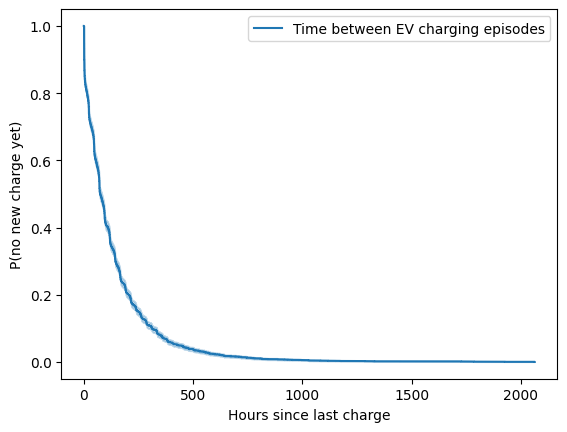

In [26]:
# How long after a charge does the next charge happen?

kmf = ll.KaplanMeierFitter()
kmf.fit(gap_times_I["gap_hours_till_next_charge"], label="Time between EV charging episodes")
kmf.plot_survival_function()

plt.xlabel("Hours since last charge")
plt.ylabel("P(no new charge yet)")
plt.show()

#Steep drop = frequent charging

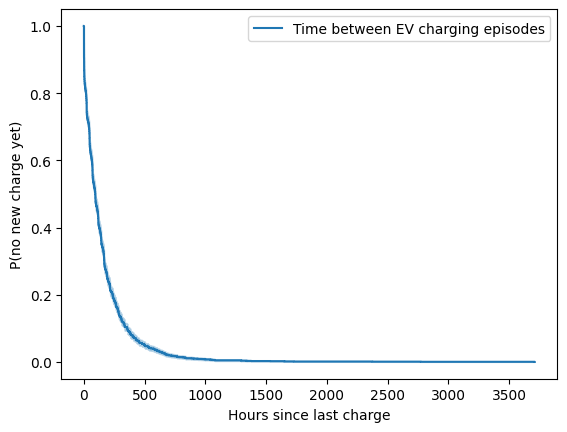

In [27]:
# How long after a charge does the next charge happen?

kmf = ll.KaplanMeierFitter()
kmf.fit(gap_times_C["gap_hours_till_next_charge"], label="Time between EV charging episodes")
kmf.plot_survival_function()

plt.xlabel("Hours since last charge")
plt.ylabel("P(no new charge yet)")
plt.show()

#Steep drop = frequent charging

## Andersen–Gill Cox model

In [ ]:
# Time between end of one charge and start of the next

cph = ll.CoxPHFitter()

cph.fit(
    gap_times[[
    "gap_hours_till_next_charge",
    "household",          # cluster
    "intervention",       # example covariate
]],
    duration_col="gap_hours_till_next_charge",
    cluster_col="household"
)

cph.print_summary()

# How does the intervention change the rate at which the next charging event occurs, conditional on the previous one?

# After the intervention, households are 12% more likely to start a new EV charging session at any given hour, compared to control --> Charging gaps are shorter under intervention.

#given two charging gaps does the model correctly assign a higher hazard to the one that actually ends sooner?

<lifelines.CoxPHFitter: fitted with 6666 total observations, 0 right-censored observations>
             duration col = 'gap_hours_till_next_charge'
              cluster col = 'household'
          robust variance = True
      baseline estimation = breslow
   number of observations = 6666
number of events observed = 6666
   partial log-likelihood = -52021.96
         time fit was run = 2026-01-29 16:27:51 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
intervention  0.11      1.12      0.04            0.02            0.20                1.02                1.22

              cmp to    z    p  -log2(p)
covariate                               
intervention    0.00 2.49 0.01      6.29
---
Concordance = 0.50
Partial AIC = 104045.92
log-likelihood ratio test = 19.99 on 1 df
-log2(p) of ll-ratio test = 16.97